In [51]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [52]:
df=pd.read_csv(r"C:\Users\Owner\Desktop\대학\cct S1\machine learning\CA1\Diabetes Dataset.csv")
#df=pd.read_Csv("Diabetes Dataset.csv")

In [53]:
df.head()

,Gender,Age,Physical Activity,Smoking Status,Alcohol Intake,Glucose,Blood Pressure,Skin Thickness,Insulin,BMI,Cholesterol,Diabetes Pedigree Function,Family History,Hypertension,Outcome
0,Male,63,Moderate,Former,NaN,103,40,7,41,28.196216,167,1.393,Yes,Yes,Diabetic
1,Female,51,Moderate,Never,Regular,104,59,21,51,30.438114,209,0.815,No,No,Diabetic
2,Female,74,Moderate,Current,NaN,128,70,18,199,38.700428,170,0.244,No,No,Diabetic
3,Male,78,Low,Never,Occasional,148,72,15,110,44.861600,170,0.336,No,No,Diabetic
4,Male,32,High,Never,NaN,102,55,18,49,21.591572,211,1.146,Yes,No,Non-diabetic


In [54]:
df.shape

(20000, 15)

In [55]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 20000 entries, 0 to 19999
Data columns (total 15 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Gender                      20000 non-null  str    
 1   Age                         20000 non-null  int64  
 2   Physical Activity           20000 non-null  str    
 3   Smoking Status              20000 non-null  str    
 4   Alcohol Intake              10075 non-null  str    
 5   Glucose                     20000 non-null  int64  
 6   Blood Pressure              20000 non-null  int64  
 7   Skin Thickness              20000 non-null  int64  
 8   Insulin                     20000 non-null  int64  
 9   BMI                         20000 non-null  float64
 10  Cholesterol                 20000 non-null  int64  
 11  Diabetes Pedigree Function  20000 non-null  float64
 12  Family History              20000 non-null  str    
 13  Hypertension                20000 non-null

In [56]:
df.describe()

,Age,Glucose,Blood Pressure,Skin Thickness,Insulin,BMI,Cholesterol,Diabetes Pedigree Function
count,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000
mean,49.565400,119.603400,69.432850,20.105450,83.952550,32.008980,189.555400,1.310665
std,17.320956,29.590699,12.016115,9.130969,53.026841,6.913271,35.081701,0.693984
min,20.000000,40.000000,30.000000,7.000000,15.000000,15.000000,100.000000,0.100000
25%,35.000000,99.000000,61.000000,13.000000,40.000000,27.314424,166.000000,0.704750
50%,50.000000,120.000000,69.000000,20.000000,79.000000,31.994040,190.000000,1.316000
75%,64.000000,140.000000,78.000000,26.000000,120.000000,36.750196,213.000000,1.914000
max,79.000000,200.000000,114.000000,57.000000,276.000000,50.000000,320.000000,2.500000


In [57]:
df.describe(include='str')

,Gender,Physical Activity,Smoking Status,Alcohol Intake,Family History,Hypertension,Outcome
count,20000,20000,20000,10075,20000,20000,20000
unique,2,3,3,2,2,2,2
top,Male,Moderate,Never,Occasional,No,No,Diabetic
freq,10028,9976,11999,6014,12083,13974,16726


In [58]:
df.isnull().sum()

Gender                           0
Age                              0
Physical Activity                0
Smoking Status                   0
Alcohol Intake                9925
Glucose                          0
Blood Pressure                   0
Skin Thickness                   0
Insulin                          0
BMI                              0
Cholesterol                      0
Diabetes Pedigree Function       0
Family History                   0
Hypertension                     0
Outcome                          0
dtype: int64

In [59]:
df['Alcohol Intake'].unique()
# none 이 nan을으로 인식됨

<StringArray>
[nan, 'Regular', 'Occasional']
Length: 3, dtype: str

In [60]:
df['Alcohol Intake']= df['Alcohol Intake'].fillna('None')

In [61]:
df['Alcohol Intake'].head()

0          None
1       Regular
2          None
3    Occasional
4          None
Name: Alcohol Intake, dtype: str

In [62]:
df['Alcohol Intake'].info()

<class 'pandas.Series'>
RangeIndex: 20000 entries, 0 to 19999
Series name: Alcohol Intake
Non-Null Count  Dtype
--------------  -----
20000 non-null  str  
dtypes: str(1)
memory usage: 156.4 KB


In [63]:
df.isnull().sum()

Gender                        0
Age                           0
Physical Activity             0
Smoking Status                0
Alcohol Intake                0
Glucose                       0
Blood Pressure                0
Skin Thickness                0
Insulin                       0
BMI                           0
Cholesterol                   0
Diabetes Pedigree Function    0
Family History                0
Hypertension                  0
Outcome                       0
dtype: int64

In [64]:
numerical_cols = [
    "Age",
    "Glucose",
    "Blood Pressure",
    "Skin Thickness",
    "Insulin",
    "BMI",
    "Cholesterol",
    "Diabetes Pedigree Function"

]

In [65]:
categorical_cols=[
    "Gender",
    "Physical Activity",
    "Smoking Status",
    "Alcohol Intake",
    "Family History",
    "Hypertension",
    "Outcome"
]

In [66]:
numerical_summary=df[numerical_cols].describe(include='all')
print(numerical_summary)

                Age       Glucose  Blood Pressure  Skin Thickness  \
count  20000.000000  20000.000000    20000.000000    20000.000000   
mean      49.565400    119.603400       69.432850       20.105450   
std       17.320956     29.590699       12.016115        9.130969   
min       20.000000     40.000000       30.000000        7.000000   
25%       35.000000     99.000000       61.000000       13.000000   
50%       50.000000    120.000000       69.000000       20.000000   
75%       64.000000    140.000000       78.000000       26.000000   
max       79.000000    200.000000      114.000000       57.000000   

            Insulin           BMI   Cholesterol  Diabetes Pedigree Function  
count  20000.000000  20000.000000  20000.000000                20000.000000  
mean      83.952550     32.008980    189.555400                    1.310665  
std       53.026841      6.913271     35.081701                    0.693984  
min       15.000000     15.000000    100.000000                   

In [67]:
categorical_summary=df[categorical_cols].astype(str).describe(include='all')
print(categorical_summary)

       Gender Physical Activity Smoking Status Alcohol Intake Family History  \
count   20000             20000          20000          20000          20000   
unique      2                 3              3              3              2   
top      Male          Moderate          Never           None             No   
freq    10028              9976          11999           9925          12083   

       Hypertension   Outcome  
count         20000     20000  
unique            2         2  
top              No  Diabetic  
freq          13974     16726  


In [68]:
df1=df.copy()

In [69]:
import sklearn.preprocessing as preproc
oe=preproc.OrdinalEncoder()
le = preproc.LabelEncoder()
 # ordinal encoder -> independent variable. 

In [70]:
print(df['Physical Activity'].unique())
print(df['Physical Activity'].value_counts())


<StringArray>
['Moderate', 'Low', 'High']
Length: 3, dtype: str
Physical Activity
Moderate    9976
Low         5995
High        4029
Name: count, dtype: int64


In [71]:
df['Physical Activity']=oe.fit_transform(df[['Physical Activity']])
#df['Physical Activity']=df['Physical Activity'].map({'Moderate':1, 'Low':0, 'High':2})
print(df['Physical Activity'].value_counts())

Physical Activity
2.0    9976
1.0    5995
0.0    4029
Name: count, dtype: int64


In [72]:
print(df['Smoking Status'].unique())
print(df['Smoking Status'].value_counts())


<StringArray>
['Former', 'Never', 'Current']
Length: 3, dtype: str
Smoking Status
Never      11999
Former      4968
Current     3033
Name: count, dtype: int64


In [73]:
df['Smoking Status']=oe.fit_transform(df[['Smoking Status']])
#df['Smoking Status']=df['Smoking Status'].map({'Moderate':1, 'Low':0, 'High':2})
print(df['Smoking Status'].value_counts())

Smoking Status
2.0    11999
1.0     4968
0.0     3033
Name: count, dtype: int64


In [74]:
print(df['Alcohol Intake'].unique())
print(df['Alcohol Intake'].value_counts())

<StringArray>
['None', 'Regular', 'Occasional']
Length: 3, dtype: str
Alcohol Intake
None          9925
Occasional    6014
Regular       4061
Name: count, dtype: int64


In [75]:
df['Alcohol Intake']=oe.fit_transform(df[['Alcohol Intake']])
print(df['Alcohol Intake'].value_counts())

Alcohol Intake
0.0    9925
1.0    6014
2.0    4061
Name: count, dtype: int64


In [76]:
print(df['Gender'].unique())
print(df['Gender'].value_counts())

<StringArray>
['Male', 'Female']
Length: 2, dtype: str
Gender
Male      10028
Female     9972
Name: count, dtype: int64


In [77]:
#df1=pd.get_dummies(df1, columns=['Gender'], dtype=int)
df['Gender'] = df['Gender'].map({'Male': 0, 'Female': 1})

In [78]:
print(df['Family History'].unique())
print(df['Family History'].value_counts())

<StringArray>
['Yes', 'No']
Length: 2, dtype: str
Family History
No     12083
Yes     7917
Name: count, dtype: int64


In [79]:
df['Family History']=df['Family History'].map({'No':0,'Yes':1})

In [80]:
print(df['Family History'].unique())
print(df['Family History'].value_counts())

[1 0]
Family History
0    12083
1     7917
Name: count, dtype: int64


In [81]:
print(df['Hypertension'].unique())
print(df['Hypertension'].value_counts())

<StringArray>
['Yes', 'No']
Length: 2, dtype: str
Hypertension
No     13974
Yes     6026
Name: count, dtype: int64


In [82]:
df['Hypertension']=df['Hypertension'].map({'Yes':1, 'No':0})

In [83]:
print(df['Hypertension'].unique())
print(df['Hypertension'].value_counts())

[1 0]
Hypertension
0    13974
1     6026
Name: count, dtype: int64


In [84]:
print(df['Outcome'].unique())
print(df['Outcome'].value_counts())

<StringArray>
['Diabetic', 'Non-diabetic']
Length: 2, dtype: str
Outcome
Diabetic        16726
Non-diabetic     3274
Name: count, dtype: int64


In [85]:
df['Outcome']=df['Outcome'].map({'Diabetic':1,"Non-diabetic":0})

In [86]:
print(df['Outcome'].unique())
print(df['Outcome'].value_counts())

[1 0]
Outcome
1    16726
0     3274
Name: count, dtype: int64


In [87]:
df.head()

,Gender,Age,Physical Activity,Smoking Status,Alcohol Intake,Glucose,Blood Pressure,Skin Thickness,Insulin,BMI,Cholesterol,Diabetes Pedigree Function,Family History,Hypertension,Outcome
0,0,63,2.0,1.0,0.0,103,40,7,41,28.196216,167,1.393,1,1,1
1,1,51,2.0,2.0,2.0,104,59,21,51,30.438114,209,0.815,0,0,1
2,1,74,2.0,0.0,0.0,128,70,18,199,38.700428,170,0.244,0,0,1
3,0,78,1.0,2.0,1.0,148,72,15,110,44.861600,170,0.336,0,0,1
4,0,32,0.0,2.0,0.0,102,55,18,49,21.591572,211,1.146,1,0,0


In [88]:
df.shape

(20000, 15)

In [89]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 20000 entries, 0 to 19999
Data columns (total 15 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Gender                      20000 non-null  int64  
 1   Age                         20000 non-null  int64  
 2   Physical Activity           20000 non-null  float64
 3   Smoking Status              20000 non-null  float64
 4   Alcohol Intake              20000 non-null  float64
 5   Glucose                     20000 non-null  int64  
 6   Blood Pressure              20000 non-null  int64  
 7   Skin Thickness              20000 non-null  int64  
 8   Insulin                     20000 non-null  int64  
 9   BMI                         20000 non-null  float64
 10  Cholesterol                 20000 non-null  int64  
 11  Diabetes Pedigree Function  20000 non-null  float64
 12  Family History              20000 non-null  int64  
 13  Hypertension                20000 non-null

"In this study, the target variable 'Outcome' was encoded as binary classes, where 'Non-diabetic' is represented by 0 and 'Diabetic' is represented by 1."

<Axes: xlabel='Outcome', ylabel='count'>

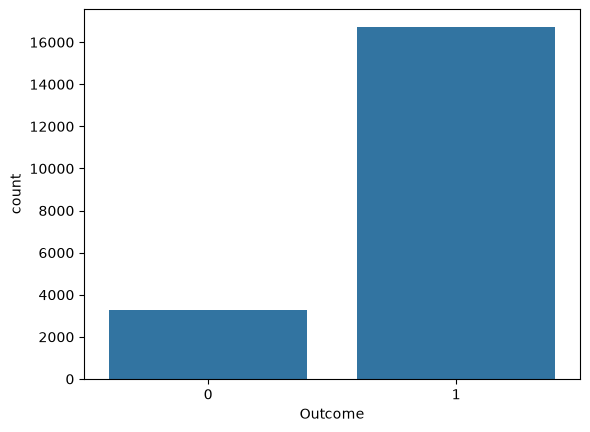

In [90]:
sns.countplot(data=df,x='Outcome')

C:\Users\Owner\AppData\Local\Temp\ipykernel_35752\2197261735.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='Outcome', y='Blood Pressure', palette='Set1')


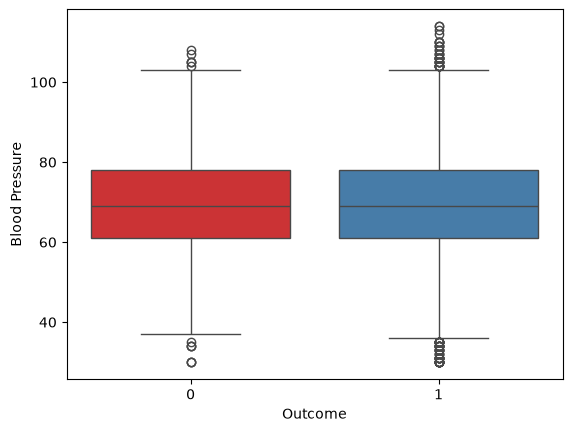

In [91]:
sns.boxplot(data=df, x='Outcome', y='Blood Pressure', palette='Set1')
plt.show()

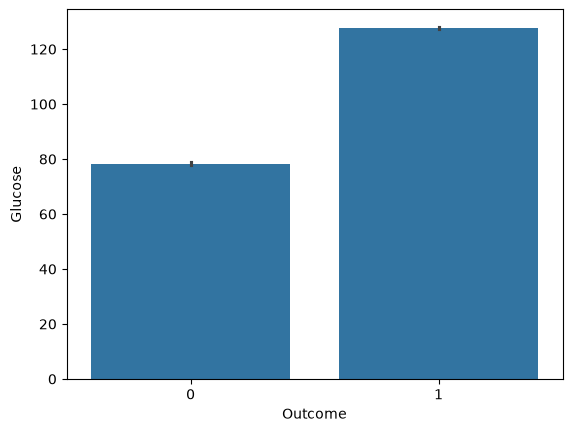

In [92]:
sns.barplot(x='Outcome', y='Glucose', data=df)
plt.show()

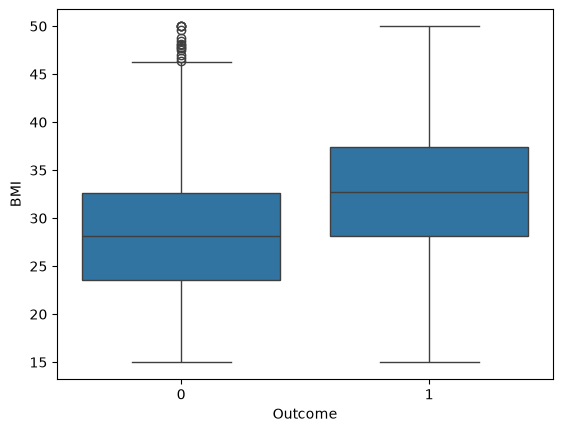

In [93]:
sns.boxplot(x='Outcome', y='BMI', data=df)
plt.show()

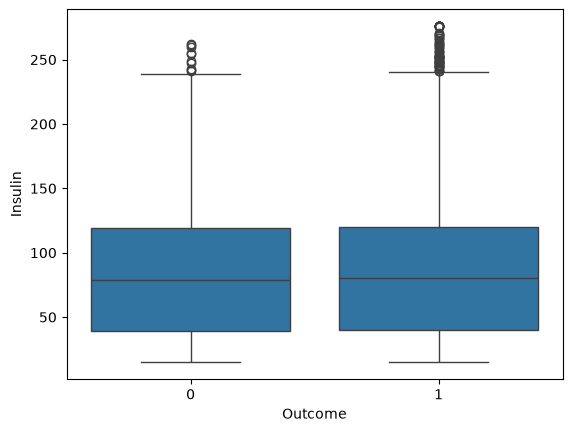

In [94]:
sns.boxplot(x='Outcome', y='Insulin', data=df)
plt.show()

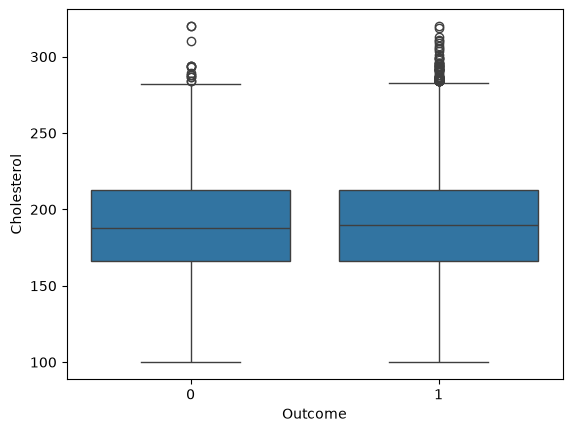

In [95]:
sns.boxplot(x='Outcome', y='Cholesterol', data=df)
plt.show()

"수치형 변수들의 박스플롯을 분석한 결과, 여러 변수(특히 Glucose, Insulin 등)에서 다수의 이상치가 관측되었습니다. 이는 데이터 수집 오류나 노이즈가 아니라, 당뇨병 환자 집단 특유의 극단적인 생체 지표 분포(오른쪽으로 치우친 형태)를 반영하는 실제 임상 데이터의 특성입니다. 머신러닝 모델(예: Random Forest 등 앙상블 모델)은 트리 기반 구조 특성상 이러한 이상치에 비교적 강건(Robust)하므로, 별도의 과도한 제거 없이 원본 분포를 유지한 채 모델 학습에 활용하였습니다."

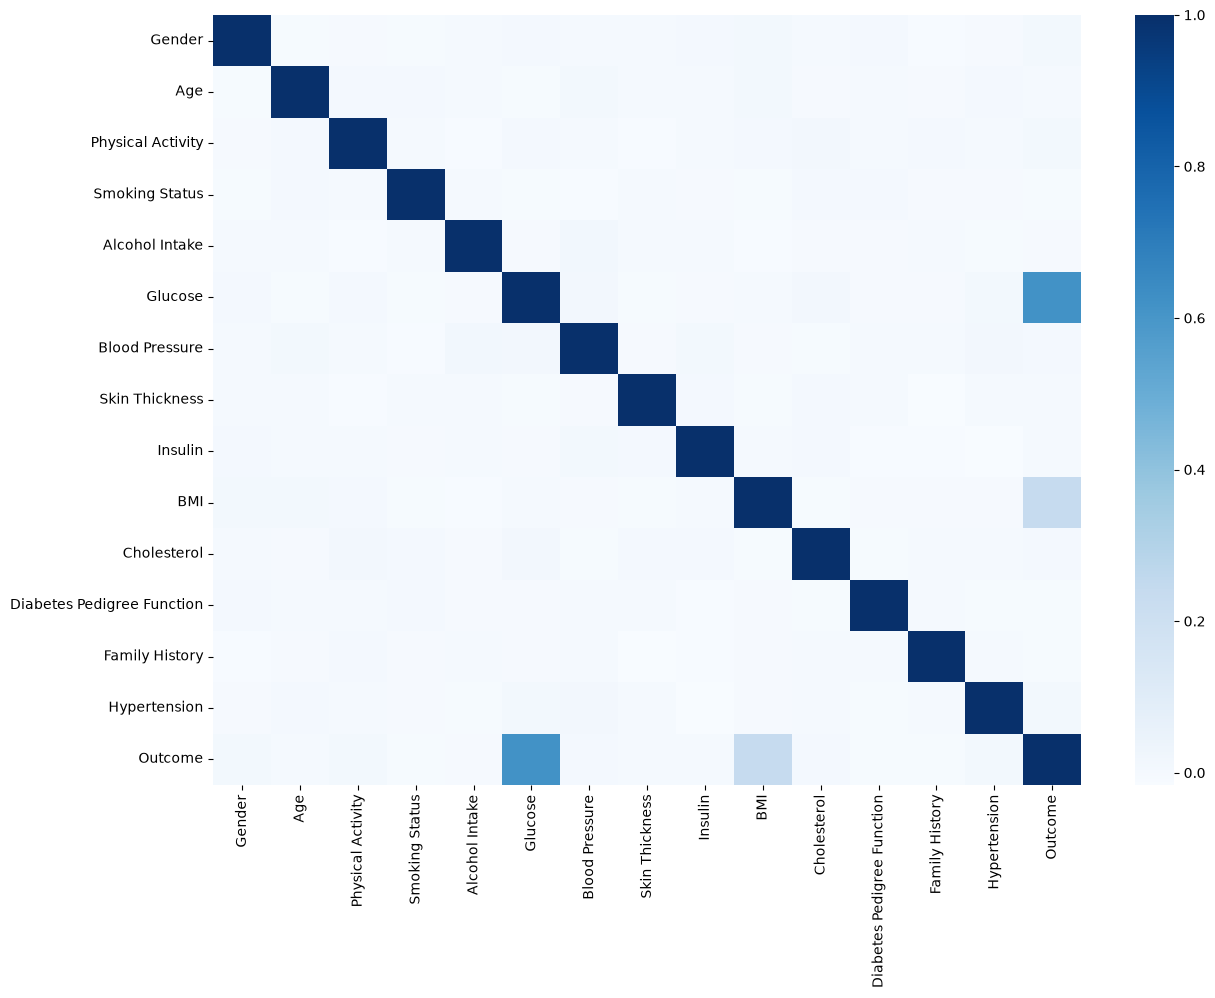

In [96]:
plt.figure(figsize=(14, 10))

corr = df.select_dtypes(include='number').corr()

sns.heatmap(
    corr,
    annot=False,
    cmap='Blues'
)
plt.show()

In [97]:
from sklearn.model_selection import train_test_split
from sklearn import metrics
from sklearn.svm import SVC

In [98]:
X=df.drop(columns=['Outcome'])
y=df['Outcome']

X_train, X_test, y_train, y_test = train_test_split(X,y, test_size=0.2, random_state=42)

In [99]:
print(X_train.shape, X_test.shape, y_train.shape, y_test.shape)

(16000, 14) (4000, 14) (16000,) (4000,)


In [100]:
import sklearn

from sklearn import set_config

set_config(display='text')

In [101]:
from sklearn.svm import SVC

svc_model = SVC()
svc_model.fit(X_train, y_train)


SVC()

In [102]:
from sklearn.metrics import classification_report, confusion_matrix

# Make predictions using the model
y_predict = svc_model.predict(X_test)

In [103]:
from sklearn.metrics import confusion_matrix

<Figure size 640x480 with 0 Axes>

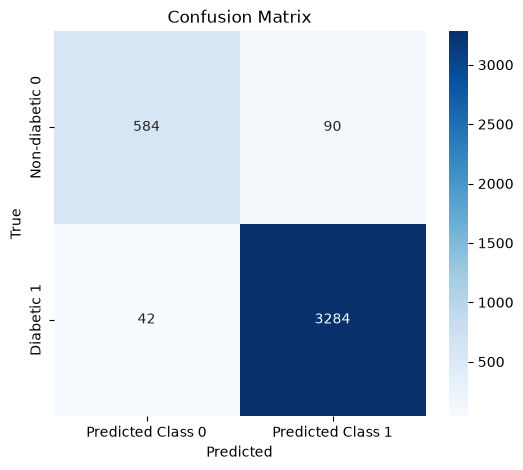

In [106]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Generate confusion matrix
cm = confusion_matrix(y_test, y_predict)

# **Ensure previous plots are cleared**
plt.clf()  # Clear the previous plot before rendering a new one
plt.figure(figsize = (6, 5))  # Define figure size to avoid residual elements

# Create a heatmap for the confusion matrix
sns.heatmap(cm, annot = True, fmt = 'd', cmap = 'Blues', 
            xticklabels=['Predicted Class 0', 'Predicted Class 1'], 
            yticklabels=['Non-diabetic 0', 'Diabetic 1'])

# Add labels and title
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Confusion Matrix')

# Show the plot
plt.show()

In [105]:
# Print classification report
print(classification_report(y_test, y_predict))

              precision    recall  f1-score   support

           0       0.93      0.87      0.90       674
           1       0.97      0.99      0.98      3326

    accuracy                           0.97      4000
   macro avg       0.95      0.93      0.94      4000
weighted avg       0.97      0.97      0.97      4000



In [107]:
#normalized scaler - fit&transform on train, fit only on test
from sklearn.preprocessing import StandardScaler
n_scaler = StandardScaler()
X_train_scaled = n_scaler.fit_transform(X_train.astype(float))
X_test_scaled = n_scaler.transform(X_test.astype(float))

#Support Vector Classification model -  apply on scaled data
from sklearn.svm import SVC
svc_model_scaled = SVC()
svc_model_scaled.fit(X_train_scaled, y_train)

SVC()

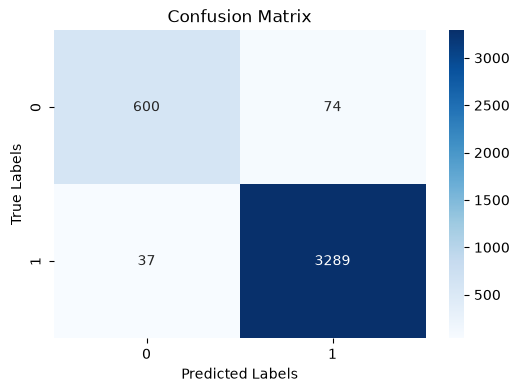

              precision    recall  f1-score   support

           0       0.94      0.89      0.92       674
           1       0.98      0.99      0.98      3326

    accuracy                           0.97      4000
   macro avg       0.96      0.94      0.95      4000
weighted avg       0.97      0.97      0.97      4000



In [109]:
# Predict
y_predict_scaled = svc_model_scaled.predict(X_test_scaled)

# Confusion matrix
cm_scaled = confusion_matrix(y_test, y_predict_scaled)

# Plot confusion matrix
plt.figure(figsize = (6, 4))
sns.heatmap(cm_scaled, annot = True, fmt = 'd', cmap = 'Blues')
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix')
plt.show()   # <-- REQUIRED to display the plot outside Jupyter

# Print classification report
print(classification_report(y_test, y_predict_scaled))

In [ ]:
# Print classification report
print(classification_report(y_test, y_predict))
#조금 나아졋지만 크게 영향 미칠 정도는 아니다

              precision    recall  f1-score   support

           0       0.93      0.87      0.90       674
           1       0.97      0.99      0.98      3326

    accuracy                           0.97      4000
   macro avg       0.95      0.93      0.94      4000
weighted avg       0.97      0.97      0.97      4000

